In [1]:
import json
import sys
from rdkit import Chem 
from rdkit.Chem import AllChem as rdkit
import py3Dmol
import stk
import stko
import numpy as np
import shutil
import os
sys.path.append('..//link') 
from link import link



In [ ]:
molecule_name = Toluene

In [31]:
with open('../SMILES/BB_info.json', 'r') as f:
    data = json.load(f)


In [33]:
for molecule_name, molecule_info in data.items():
    for BB_name, BB_info in molecule_info['BB'].items():
        molecule = molecule_name
        smiles = data[molecule]["smiles"]
        print(molecule,BB_name)
        if 'Br' in  data[molecule]['BB'][BB_name]:
            Br_num = data[molecule]['BB'][BB_name]['Br']

        else:
            Br_num = None

        if 'I' in  data[molecule]['BB'][BB_name]:
            I_num = data[molecule]['BB'][BB_name]['I']

        else:
            I_num = None

        if 'F' in  data[molecule]['BB'][BB_name]:
            F_num = data[molecule]['BB'][BB_name]['F']

        else:
            F_num = None

        building_block = stk.BuildingBlock(smiles)
        mol_rdkit =  building_block.to_rdkit_mol()
        atom = list(mol_rdkit.GetAtoms())

        for n, a in enumerate(atom):
            if Br_num is not None and n+1 in Br_num: #變數
                a.SetAtomicNum(35) #Br
            if I_num is not None and n+1 in I_num:
                a.SetAtomicNum(53) #I 
            if F_num is not None and n+1 in F_num:
                a.SetAtomicNum(9) #F

        atom_num = [ a.GetAtomicNum() for a in atom]
        atomdic = {}
        for n,a in enumerate(atom_num):
            if a == 6:
                atomdic[str(n+1)] = f'{"C"+str(n+1)}'
            if a == 1:
                atomdic[str(n+1)] = f'{"H"+str(n+1)}'
            if a == 7:
                atomdic[str(n+1)] = f'{"N"+str(n+1)}'
            if a == 8:
                atomdic[str(n+1)] = f'{"O"+str(n+1)}'
            if a == 16:
                atomdic[str(n+1)] = f'{"S"+str(n+1)}'

        with open(f'../qforce_rtp/{BB_name}.rtp','w') as rtp:
            rtp.write("[ bondedtypes ]\n")
            rtp.write("; bonds   angles dihedrals impropers\n")
            rtp.write(f"    1        1        3        2\n\n")
            rtp.write(f"[ {BB_name} ]\n")
            rtp.write(f"  [ atoms ]\n")
            for n,a in enumerate(atom_num):
                number = n+1
                if a == 6:
                    rtp.write(f'    {"C"+str(number):<5} {BB_name+"_C"+str(number):<8}\n')
                elif a == 1:
                    rtp.write(f'    {"H"+str(number):<5} {BB_name+"_H"+str(number):<8}\n')
                elif a == 7:
                    rtp.write(f'    {"N"+str(number):<5} {BB_name+"_N"+str(number):<8}\n')
                elif a == 8:
                    rtp.write(f'    {"O"+str(number):<5} {BB_name+"_O"+str(number):<8}\n')
                elif a == 16:
                    rtp.write(f'    {"S"+str(number):<5} {BB_name+"_S"+str(number):<8}\n')

            rtp.write("\n  [ bonds ]\n")

            with open(f'../BB_hessian/{molecule}_qforce/{molecule}_qforce.itp','r') as f: 
                lines = f.readlines()
                for index,i in enumerate(lines):
                    if '[ bonds ]' in i:
                        start = index+1
                    elif '[ angles ]' in i:
                        end = index
                        break 
                for i in lines[start:end]:
                    tmp = i.split()
                    try:
                        if tmp[0] in atomdic and tmp[1] in atomdic:
                            rtp.write(f'    {atomdic[tmp[0]]:<5} {atomdic[tmp[1]]:<5}\n')
                    except ValueError:
                        continue
                    except IndexError:
                        break
                
            rtp.write("\n  [ impropers ]\n")
            for index,i in enumerate(lines):
                if '[ dihedrals ]' in i:
                    start = index+1
                elif '[ pairs ]' in i:
                    end = index
                    break
                elif '; flexible dihedrals' in i:
                    end = index
                    break

            for i in lines[start:end]:
                tmp = i.split()
                try:
                    if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic and tmp[3] in atomdic:
                        rtp.write(f'    {atomdic[tmp[0]]:<5} {atomdic[tmp[1]]:<5} {atomdic[tmp[2]]:<5} {atomdic[tmp[3]]}\n')
                except ValueError:
                    continue
                except IndexError:
                    break

        with open(f'../qforce_itp/{BB_name}.itp','w') as itp:
            itp.write('[ bondtypes ]\n')

            for index,i in enumerate(lines):
                if '[ bonds ]' in i:
                    start = index+1
                elif '[ angles ]' in i:
                    end = index
                    break 
            for i in lines[start:end]:
                tmp = i.split()
                try:
                    if tmp[0] in atomdic and tmp[1] in atomdic:
                        itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {tmp[2]:<8} {tmp[3]:<10} {tmp[4]:<10}\n')
                except ValueError:
                    continue
                except IndexError:
                    break

            itp.write('\n[ angletypes ]\n')

            for index,i in enumerate(lines):
                if '[ angles ]' in i:
                    start = index+1
                elif '[ dihedrals ]' in i:
                    end = index


            for i in lines[start:end]:
                tmp = i.split()
                try:
                    if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic:
                        itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {BB_name+"_"+atomdic[tmp[2]]:<10}  {tmp[3]:<8} {tmp[4]:<10} {tmp[5]:<10}\n')
                except ValueError:
                    continue
                except IndexError:
                    break

            itp.write('\n[ dihedraltypes ]\n')

            for index,i in enumerate(lines):
                if '[ dihedrals ]' in i:
                    start = index+1
                elif '[ pairs ]' in i:
                    end = index
                    break 
                elif '; flexible dihedrals' in i:
                    end = index
                    break     
                
            for i in lines[start:end]:
                tmp = i.split()
                try:
                    if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic and tmp[3] in atomdic:
                        itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {BB_name+"_"+atomdic[tmp[2]]:<10} {BB_name+"_"+atomdic[tmp[3]]:<10}  {tmp[4]:<8} {tmp[5]:<10} {tmp[6]:<10}\n')
                except ValueError:
                    continue
                except IndexError:
                    break        

Benzene 1BA
Benzene 1BB
Benzene 1BC
Benzene 1BD
Benzene 1BE
Benzene 1BF
Benzene 1BG
Benzene 1BH
Toluene TLA
Toluene TLB
Toluene TLC
Butylbenzene BUA
Benzonitrile BNA
Benzonitrile BNB
Benzonitrile BNC
Naphthalene NAA
Naphthalene NAB
Anthracene ANA
Anthracene ANB
2Methylanthracene MAA
2_tert_Butylanthracene TBA
Phenanthrene PNA
Pyrene PYA
Pyrene PYB
Fluorene FLA
Fluorene FLB
Fluorene FLC
Fluorene FLD
9_9_Dimethyl_9H_fluorene MFA
9_9_Dimethyl_9H_fluorene MFB
Spirobifluorene SFA
Spirobifluorene SFB
Spirobifluorene SFC
Spirobifluorene SFD
Spirobifluorene SFE
Pyridine PDA
Pyridine PDB
Pyridine PDC
Pyridine PDD
Pyridine PDE
Pyridine PDF
Pyridine PDG
3_Cyanopyridine CPA
Pyrimidine PMA
Triazine TIA
Triazole TOA
Isoquinoline IQA
Quinoline QNA
1_8_Naphthyridine NYA
Benzimidazole BMA
Carbazole CBA
Carbazole CBB
Carbazole CBC
Carbazole_3_carbonitrile CNA
Pyrido_2_3_b_indole P2A
Pyrido_3_2_b_indole P3A
5H_Pyrido_4_3_b_indole P4A
Phenanthro_9_10_d_imidazole PIA
1_10_Phenanthroline PTA
1_10_Phenanthro

In [26]:
BB_name = "BUA"

In [27]:
for molecule_name, molecule_info in data.items():
    for BB in data[molecule_name]["BB"]:
        if BB == BB_name:
            molecule = molecule_name
            smiles = data[molecule]["smiles"]
            print(molecule)

            if 'Br' in  data[molecule]['BB'][BB_name]:
                Br_num = data[molecule]['BB'][BB_name]['Br']

            else:
                Br_num = None

            if 'I' in  data[molecule]['BB'][BB_name]:
                I_num = data[molecule]['BB'][BB_name]['I']

            else:
                I_num = None

            if 'F' in  data[molecule]['BB'][BB_name]:
                F_num = data[molecule]['BB'][BB_name]['F']

            else:
                F_num = None

building_block = stk.BuildingBlock(smiles)
mol_rdkit =  building_block.to_rdkit_mol()
atom = list(mol_rdkit.GetAtoms())

for n, a in enumerate(atom):
    if Br_num is not None and n+1 in Br_num: #變數
        a.SetAtomicNum(35) #Br
    if I_num is not None and n+1 in I_num:
        a.SetAtomicNum(53) #I 
    if F_num is not None and n+1 in F_num:
        a.SetAtomicNum(9) #F

atom_num = [ a.GetAtomicNum() for a in atom]
atomdic = {}
for n,a in enumerate(atom_num):
    if a == 6:
        atomdic[str(n+1)] = f'{"C"+str(n+1)}'
    if a == 1:
        atomdic[str(n+1)] = f'{"H"+str(n+1)}'
    if a == 7:
        atomdic[str(n+1)] = f'{"N"+str(n+1)}'
    if a == 8:
        atomdic[str(n+1)] = f'{"O"+str(n+1)}'
    if a == 16:
        atomdic[str(n+1)] = f'{"S"+str(n+1)}'

#test = stk.BuildingBlock.init_from_rdkit_mol(mol_rdkit)
#stk.XyzWriter().write(test ,f'../test.xyz')

atomdic

Butylbenzene


{'1': 'C1',
 '2': 'C2',
 '3': 'C3',
 '4': 'C4',
 '5': 'C5',
 '6': 'C6',
 '7': 'C7',
 '8': 'C8',
 '9': 'C9',
 '10': 'C10',
 '11': 'H11',
 '12': 'H12',
 '13': 'H13',
 '14': 'H14',
 '15': 'H15',
 '16': 'H16',
 '17': 'H17',
 '18': 'H18',
 '19': 'H19',
 '20': 'H20',
 '21': 'H21',
 '23': 'H23',
 '24': 'H24'}

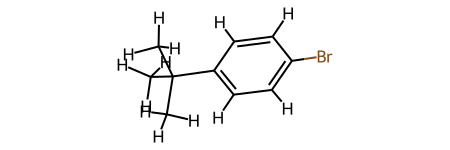

In [18]:
mol_rdkit

# 寫rtp

In [28]:
with open(f'../qforce_rtp/{BB_name}.rtp','w') as rtp:
    rtp.write("[ bondedtypes ]\n")
    rtp.write("; bonds   angles dihedrals impropers\n")
    rtp.write(f"    1        1        3        2\n\n")
    rtp.write(f"[ {BB_name} ]\n")
    rtp.write(f"  [ atoms ]\n")
    for n,a in enumerate(atom_num):
        number = n+1
        if a == 6:
            rtp.write(f'    {"C"+str(number):<5} {BB_name+"_C"+str(number):<8}\n')
        elif a == 1:
            rtp.write(f'    {"H"+str(number):<5} {BB_name+"_H"+str(number):<8}\n')
        elif a == 7:
            rtp.write(f'    {"N"+str(number):<5} {BB_name+"_N"+str(number):<8}\n')
        elif a == 8:
            rtp.write(f'    {"O"+str(number):<5} {BB_name+"_O"+str(number):<8}\n')
        elif a == 16:
            rtp.write(f'    {"S"+str(number):<5} {BB_name+"_S"+str(number):<8}\n')

    rtp.write("\n  [ bonds ]\n")

    with open(f'../BB_hessian/{molecule}_qforce/{molecule}_qforce.itp','r') as f: 
        lines = f.readlines()
        for index,i in enumerate(lines):
            if '[ bonds ]' in i:
                start = index+1
            elif '[ angles ]' in i:
                end = index
                break 
        for i in lines[start:end]:
            tmp = i.split()
            try:
                if tmp[0] in atomdic and tmp[1] in atomdic:
                    rtp.write(f'    {atomdic[tmp[0]]:<5} {atomdic[tmp[1]]:<5}\n')
            except ValueError:
                continue
            except IndexError:
                break
            
        rtp.write("\n  [ impropers ]\n")
        for index,i in enumerate(lines):
            if '[ dihedrals ]' in i:
                start = index+1
            elif '[ pairs ]' in i:
                end = index
                continue
            elif '; flexible dihedrals' in i:
                end = index
                break     
            
        for i in lines[start:end]:
            tmp = i.split()
            try:
                if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic and tmp[3] in atomdic:
                    rtp.write(f'    {atomdic[tmp[0]]:<5} {atomdic[tmp[1]]:<5} {atomdic[tmp[2]]:<5} {atomdic[tmp[3]]}\n')
            except ValueError:
                continue
            except IndexError:
                break

# 寫itp

In [29]:
with open(f'../qforce_itp/{BB_name}.itp','w') as itp:
    with open(f'../BB_hessian/{molecule}_qforce/{molecule}_qforce.itp','r') as f: 
        itp.write('[ bondtypes ]\n')
        lines = f.readlines()
        for index,i in enumerate(lines):
            if '[ bonds ]' in i:
                start = index+1
            elif '[ angles ]' in i:
                end = index
                break 
        for i in lines[start:end]:
            tmp = i.split()
            try:
                if tmp[0] in atomdic and tmp[1] in atomdic:
                    itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {tmp[2]:<8} {tmp[3]:<10} {tmp[4]:<10}\n')
            except ValueError:
                continue
            except IndexError:
                break

        itp.write('\n[ angletypes ]\n')

        for index,i in enumerate(lines):
            if '[ angles ]' in i:
                start = index+1
            elif '[ dihedrals ]' in i:
                end = index
                break 

        for i in lines[start:end]:
            tmp = i.split()
            try:
                if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic:
                    itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {BB_name+"_"+atomdic[tmp[2]]:<10}  {tmp[3]:<8} {tmp[4]:<10} {tmp[5]:<10}\n')
            except ValueError:
                continue
            except IndexError:
                break

        itp.write('\n[ dihedraltypes ]\n')

        for index,i in enumerate(lines):
            if '[ dihedrals ]' in i:
                start = index+1
            elif '[ pairs ]' in i:
                end = index
            elif '; flexible dihedrals' in i:
                end = index
                break     
                     
        for i in lines[start:end]:
            tmp = i.split()
            try:
                if tmp[0] in atomdic and tmp[1] in atomdic and tmp[2] in atomdic and tmp[3] in atomdic:
                    itp.write(f'    {BB_name+"_"+atomdic[tmp[0]]:<10} {BB_name+"_"+atomdic[tmp[1]]:<10} {BB_name+"_"+atomdic[tmp[2]]:<10} {BB_name+"_"+atomdic[tmp[3]]:<10}  {tmp[4]:<8} {tmp[5]:<10} {tmp[6]:<10}\n')
            except ValueError:
                continue
            except IndexError:
                break